**Name:** Khushi Patel  
**GitHub Username:** khushigi-a11y  
**USC ID:** 4163615025

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, _tree
from sklearn.model_selection import StratifiedKFold, cross_val_score,GridSearchCV, KFold
from sklearn.metrics import accuracy_score
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.impute import SimpleImputer

## Part (a) — Load and inspect the dataset

In [2]:
# path to the dataset
data_path = Path("../data/acute+inflammations/diagnosis.data")

# Defining column names
columns = [
    "temperature",
    "nausea",
    "lumbar-pain",
    "urine-pushing",
    "micturition-pains",
    "burning-urethra",
    "bladder-inflammation",
    "nephritis"
]

# Loading the dataset from the local file
dataset = pd.read_csv(
    data_path,
    sep=r"\s+",
    header=None,
    names=columns,
    encoding="utf-16",
    decimal=","
)

# Separating the input features and target variables
X_raw = dataset.iloc[:, :6].copy()
y_raw = dataset.iloc[:, 6:].copy()

# Displaying dimensions and first five rows
print("Features:", X_raw.shape, "Targets:", y_raw.shape)

display(X_raw.head(), y_raw.head())

Features: (120, 6) Targets: (120, 2)


,temperature,nausea,lumbar-pain,urine-pushing,micturition-pains,burning-urethra
0,35.5,no,yes,no,no,no
1,35.9,no,no,yes,yes,yes
2,35.9,no,yes,no,no,no
3,36.0,no,no,yes,yes,yes
4,36.0,no,yes,no,no,no


,bladder-inflammation,nephritis
0,no,no
1,yes,no
2,no,no
3,yes,no
4,no,no


In [3]:
# Converting input features into numeric values
X = X_raw.copy()

for col in X.columns:
    if col == "temperature":
        # Converting temperature values using decimal points
        X[col] = pd.to_numeric(
            X[col].astype(str).str.replace(",", ".")
        )
    else:
        # Converting yes/no values into 1/0
        X[col] = (
            X[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .map({"yes": 1, "no": 0})
        )

# Converting target labels into numeric values
y = y_raw.copy()

for col in y.columns:
    y[col] = (
        y[col]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"yes": 1, "no": 0})
    )

print(X.head())
print(y.head())
print("Missing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum().sum())

   temperature  nausea  lumbar-pain  urine-pushing  micturition-pains  \
0         35.5       0            1              0                  0   
1         35.9       0            0              1                  1   
2         35.9       0            1              0                  0   
3         36.0       0            0              1                  1   
4         36.0       0            1              0                  0   

   burning-urethra  
0                0  
1                1  
2                0  
3                1  
4                0  
   bladder-inflammation  nephritis
0                     0          0
1                     1          0
2                     0          0
3                     1          0
4                     0          0
Missing values in X: 0
Missing values in y: 0


## (b) Decision Tree Classification

Build a decision tree using the entire dataset and visualize the resulting tree.

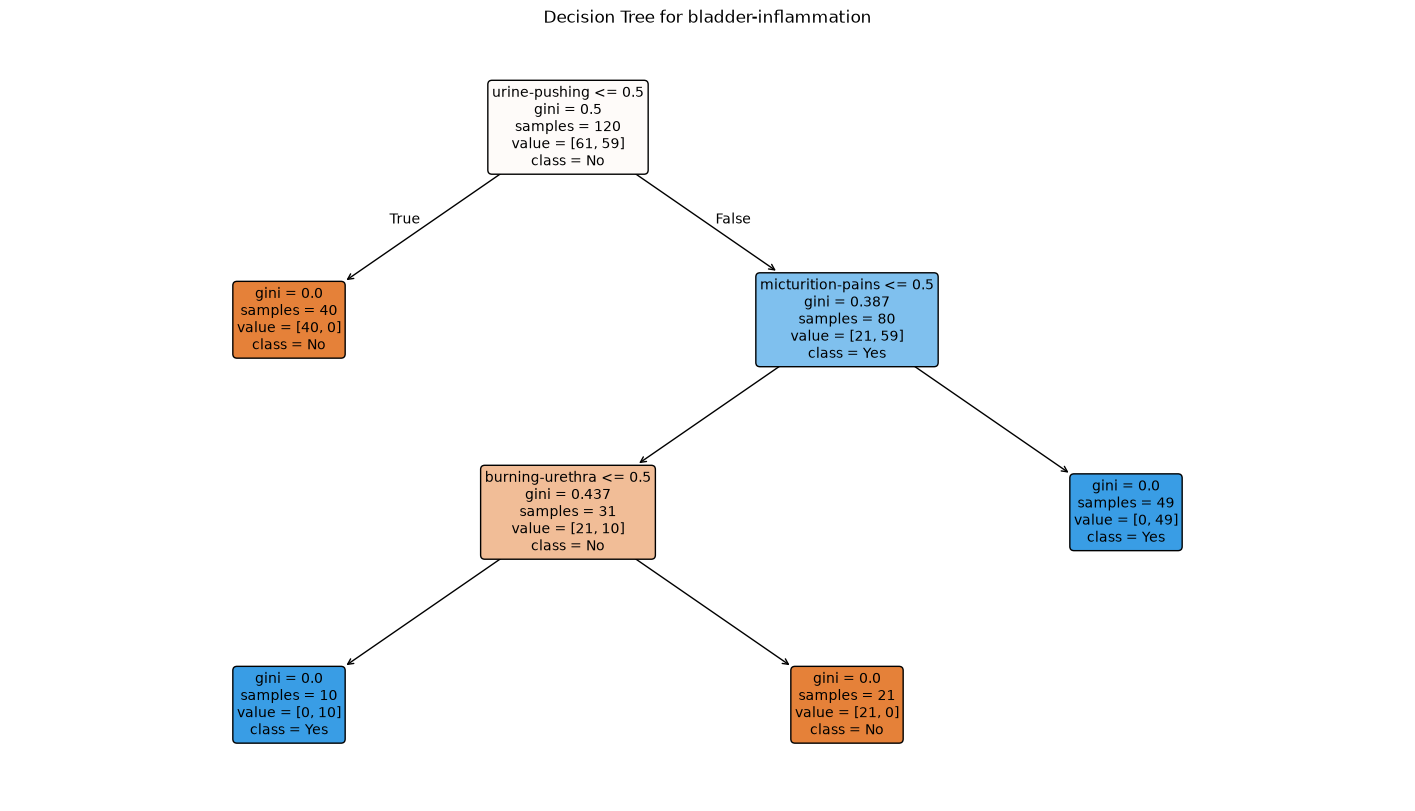

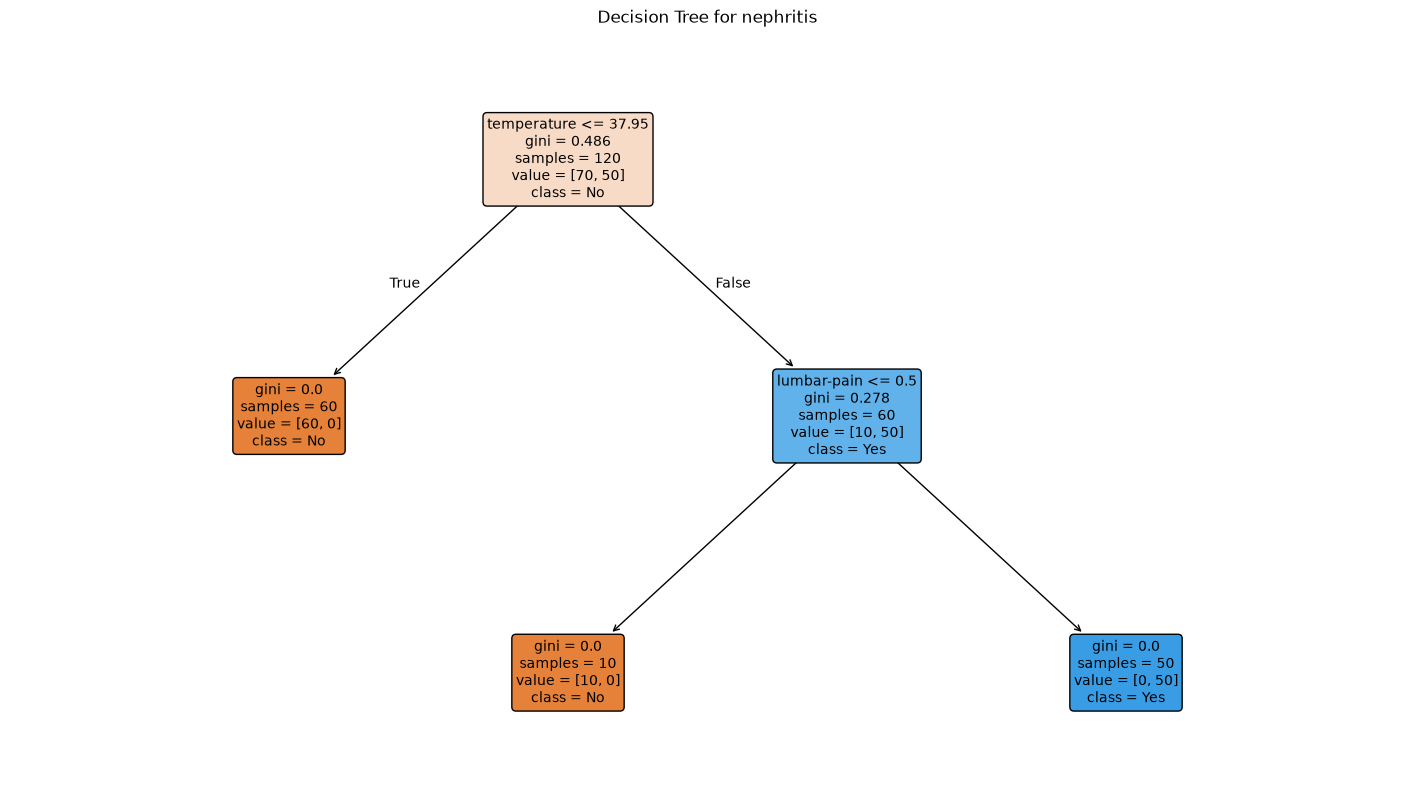

In [4]:
# Training and visualizing a decision tree 
trees = {}

for target in y.columns:
    clf = DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    )

    clf.fit(X, y[target])
    trees[target] = clf

    plt.figure(figsize=(18, 10))

    plot_tree(
        clf,
        feature_names=X.columns,
        class_names=["No", "Yes"],
        filled=True,
        rounded=True,
        fontsize=10
    )

    plt.title(f"Decision Tree for {target}")
    plt.show()

## (c) IF-THEN Decision Rules


In [5]:
def extract_rules(clf, feature_names):
    # Accessing the trained decision tree structure
    tree = clf.tree_
    features = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else None
        for i in tree.feature
    ]

    # Recursively traversing through the tree
    def traverse(node, conditions):
        if tree.feature[node] != _tree.TREE_UNDEFINED:
            feature = features[node]
            threshold = tree.threshold[node]

            # Left branch: feature value <= threshold
            traverse(
                tree.children_left[node],
                conditions + [f"{feature} <= {threshold:.2f}"]
            )

            # Right branch: feature value > threshold
            traverse(
                tree.children_right[node],
                conditions + [f"{feature} > {threshold:.2f}"]
            )
        else:
            # determining the predicted diagnosis
            predicted_class = clf.classes_[tree.value[node][0].argmax()]
            diagnosis = "Yes" if predicted_class == 1 else "No"

            print(
                f"IF {' AND '.join(conditions) if conditions else 'TRUE'} "
                f"THEN Diagnosis = {diagnosis}"
            )

    traverse(0, [])


# Extracting and displaying rules for each diagnosis
for target, clf in trees.items():
    print(f"\nIF-THEN Rules for {target}:\n")
    extract_rules(clf, list(X.columns))
    print("-" * 60)


IF-THEN Rules for bladder-inflammation:

IF urine-pushing <= 0.50 THEN Diagnosis = No
IF urine-pushing > 0.50 AND micturition-pains <= 0.50 AND burning-urethra <= 0.50 THEN Diagnosis = Yes
IF urine-pushing > 0.50 AND micturition-pains <= 0.50 AND burning-urethra > 0.50 THEN Diagnosis = No
IF urine-pushing > 0.50 AND micturition-pains > 0.50 THEN Diagnosis = Yes
------------------------------------------------------------

IF-THEN Rules for nephritis:

IF temperature <= 37.95 THEN Diagnosis = No
IF temperature > 37.95 AND lumbar-pain <= 0.50 THEN Diagnosis = No
IF temperature > 37.95 AND lumbar-pain > 0.50 THEN Diagnosis = Yes
------------------------------------------------------------


## Part (d) — Cost-complexity pruning

In [6]:
# Applying cost-complexity pruning for each diagnosis
pruned_models = {}

for target in y.columns:
    target_y = y[target]

    # getting the candidate pruning alpha values
    path = trees[target].cost_complexity_pruning_path(X, target_y)
    alphas = np.unique(path.ccp_alphas)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    rows = []

    # checking each alpha using 5-fold cross-validation
    for alpha in alphas:
        candidate = DecisionTreeClassifier(
            random_state=42,
            ccp_alpha=float(alpha)
        )

        scores = cross_val_score(
            candidate, X, target_y,
            cv=cv, scoring="accuracy"
        )

        candidate.fit(X, target_y)

        rows.append({
            "alpha": alpha,
            "cv_mean": scores.mean(),
            "cv_se": scores.std(ddof=1) / np.sqrt(len(scores)),
            "leaves": candidate.get_n_leaves()
        })

    results = pd.DataFrame(rows)

    # Selecting the simplest tree within one standard error
    best = results.loc[results.cv_mean.idxmax()]

    eligible = results[
        results.cv_mean >= best.cv_mean - best.cv_se
    ]

    selected = eligible.sort_values(
        ["leaves", "cv_mean", "alpha"],
        ascending=[True, False, False]
    ).iloc[0]

    # Fitting the final pruned tree
    pruned = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=float(selected.alpha)
    )

    pruned.fit(X, target_y)
    pruned_models[target] = pruned

    # Displaying pruning results
    print(f"\nTARGET: {target}")
    print(f"Selected alpha: {selected.alpha:.6g}")
    print(f"CV accuracy: {selected.cv_mean:.3f}")
    print(f"Full tree leaves: {trees[target].get_n_leaves()}")
    print(f"Pruned tree leaves: {pruned.get_n_leaves()}")
    print(f"Pruned tree depth: {pruned.get_depth()}")

    # Displaying IF-THEN rules using the function from Part (c)
    print("\nPruned IF-THEN Rules:")
    extract_rules(pruned, list(X.columns))

    print("-" * 60)


TARGET: bladder-inflammation
Selected alpha: 0
CV accuracy: 1.000
Full tree leaves: 4
Pruned tree leaves: 4
Pruned tree depth: 3

Pruned IF-THEN Rules:
IF urine-pushing <= 0.50 THEN Diagnosis = No
IF urine-pushing > 0.50 AND micturition-pains <= 0.50 AND burning-urethra <= 0.50 THEN Diagnosis = Yes
IF urine-pushing > 0.50 AND micturition-pains <= 0.50 AND burning-urethra > 0.50 THEN Diagnosis = No
IF urine-pushing > 0.50 AND micturition-pains > 0.50 THEN Diagnosis = Yes
------------------------------------------------------------

TARGET: nephritis
Selected alpha: 0
CV accuracy: 1.000
Full tree leaves: 3
Pruned tree leaves: 3
Pruned tree depth: 2

Pruned IF-THEN Rules:
IF temperature <= 37.95 THEN Diagnosis = No
IF temperature > 37.95 AND lumbar-pain <= 0.50 THEN Diagnosis = No
IF temperature > 37.95 AND lumbar-pain > 0.50 THEN Diagnosis = Yes
------------------------------------------------------------


## 2(a) Load and Split the Dataset


In [7]:
# Loading the feature names from the dataset
names_path = "../data/communities+and+crime/communities.names"
data_path = "../data/communities+and+crime/communities.data"

columns = []

with open(names_path, "r", encoding="latin-1") as f:
    for line in f:
        if line.startswith("@attribute"):
            columns.append(line.split()[1])

# Loading dataset
df = pd.read_csv(
    data_path,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset shape:", df.shape)
display(df.head())

# Splitting data using the original row order
train_df = df.iloc[:1495].copy()
test_df = df.iloc[1495:].copy()

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Dataset shape: (1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


Training shape: (1495, 128)
Testing shape: (499, 128)


## (b) Data Preprocessing

In [8]:
# Removing the nonpredictive features
nonpredictive = [
    "state",
    "county",
    "community",
    "communityname",
    "fold"
]

train_df = train_df.drop(columns=nonpredictive)
test_df = test_df.drop(columns=nonpredictive)

# Separating predictors and target
target = "ViolentCrimesPerPop"

X_train = train_df.drop(columns=[target])
y_train = train_df[target]

X_test = test_df.drop(columns=[target])
y_test = test_df[target]

# Checking missing values
print("Missing values before imputation:")
print(X_train.isna().sum().sum())
print(X_test.isna().sum().sum())

# Median imputation
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("\nMissing values after imputation:")
print(X_train.isna().sum().sum())
print(X_test.isna().sum().sum())

print("\nFinal shapes:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Missing values before imputation:
27633
9218

Missing values after imputation:
0
0

Final shapes:
X_train: (1495, 122)
X_test: (499, 122)


Missing values were handled using median imputation. The median of each feature was calculated from the training set and used to replace missing values in both the training and test sets. 

## (c) Correlation Matrix

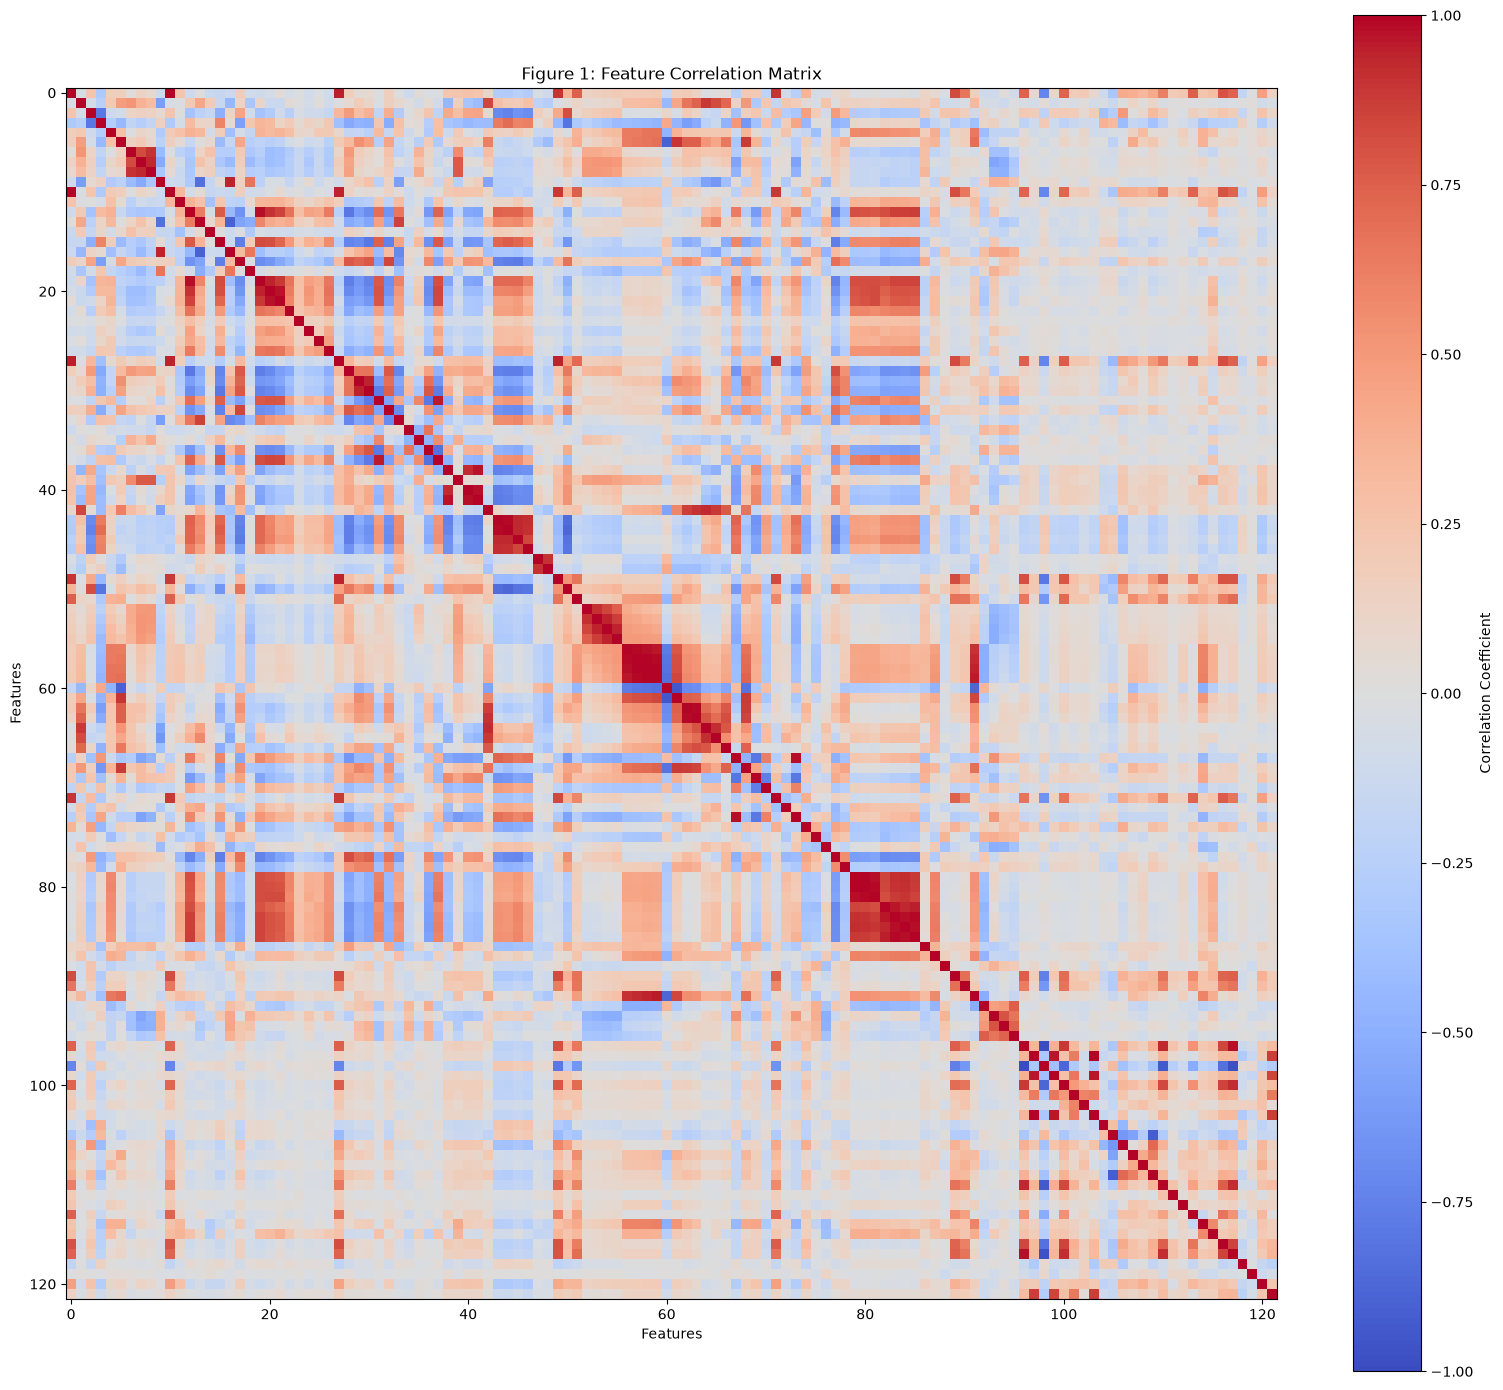

In [9]:
# Calculating the correlation matrix
corr_matrix = X_train.corr()

# Plotting the correlation matrix
plt.figure(figsize=(16, 14))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation Coefficient")

plt.title("Figure 1: Feature Correlation Matrix")
plt.xlabel("Features")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## (d) Coefficient of Variation

In [10]:
# Calculating the mean and sample standard deviation
feature_mean = X_train.mean()
feature_std = X_train.std(ddof=1)

# Calculating the coefficient of variation
cv = feature_std / feature_mean.replace(0, np.nan)

# Sorting the features by CV
cv_sorted = cv.sort_values(ascending=False)

print("Coefficient of Variation for each feature:")
print(cv_sorted.to_string())

Coefficient of Variation for each feature:
PctPolicAsian            5.527059
NumStreet                4.292923
NumInShelters            3.470952
NumIlleg                 3.058964
NumImmig                 2.926635
LemasPctOfficDrugUn      2.552946
NumUnderPov              2.342443
LemasSwornFT             2.248042
population               2.241105
numbUrban                2.038461
HousVacant               1.968467
PolicOperBudg            1.645508
LandArea                 1.645408
racePctHisp              1.612091
PctNotSpeakEnglWell      1.456618
LemasTotalReq            1.451887
racepctblack             1.428885
PctUsePubTrans           1.397110
racePctAsian             1.359100
PctPolicHisp             1.353882
PctRecentImmig           1.288287
PctRecImmig5             1.286184
PctRecImmig10            1.270476
PctRecImmig8             1.265579
OfficAssgnDrugUnits      1.174565
PctPersDenseHous         1.132926
PolicCars                1.112831
PctForeignBorn           1.065880
PctVa

## (e) Scatter Plots and Box Plots

In [11]:
# Select 11 features with highest CV
top_features = cv_sorted.head(11).index.tolist()

print("Top 11 features with highest CV:")
print(cv_sorted.head(11))

Top 11 features with highest CV:
PctPolicAsian          5.527059
NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
NumUnderPov            2.342443
LemasSwornFT           2.248042
population             2.241105
numbUrban              2.038461
HousVacant             1.968467
dtype: float64


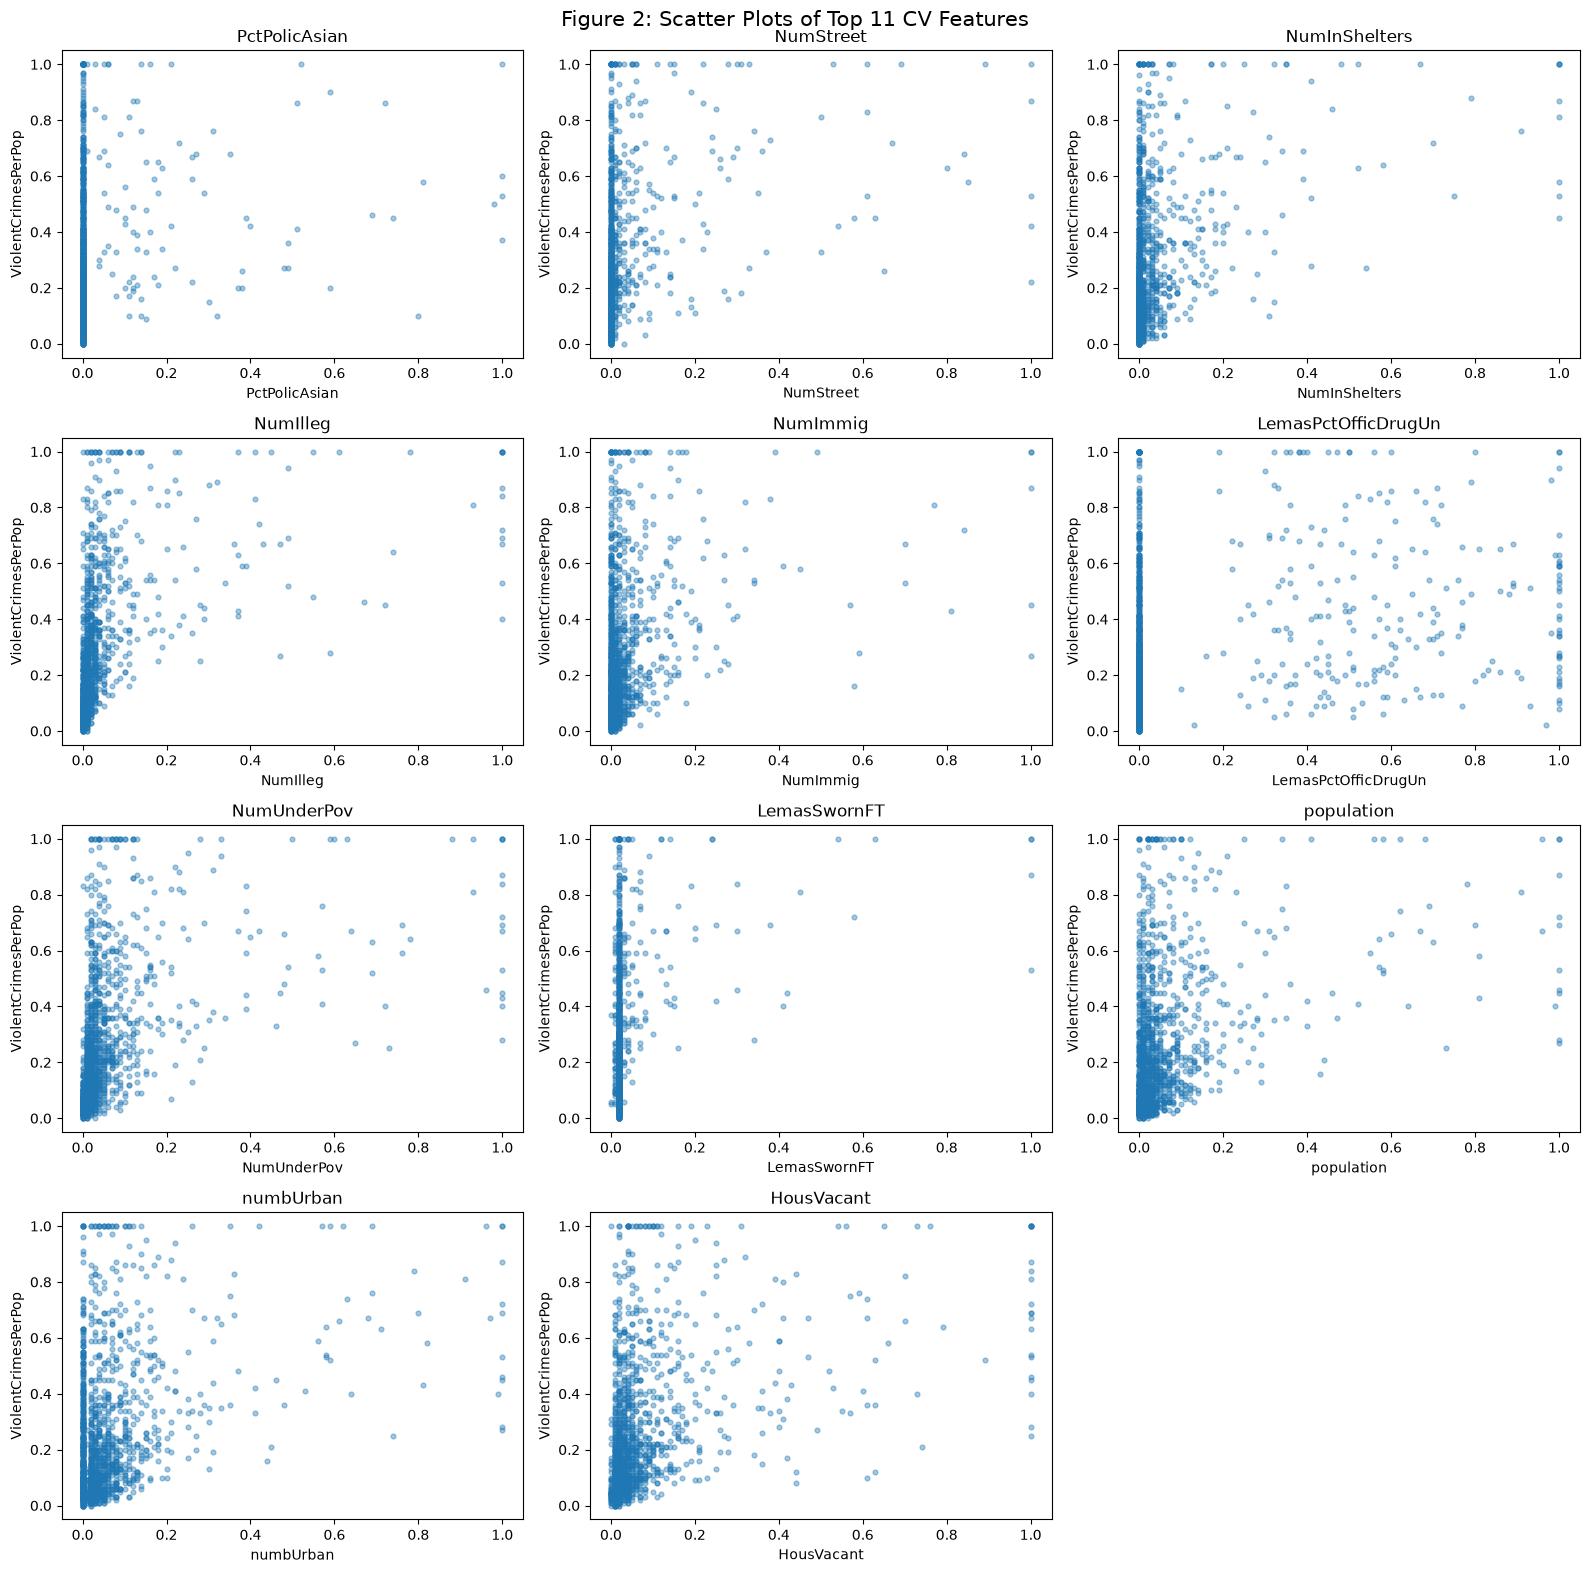

In [12]:
# Scatter plots against the target variable
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(
        X_train[feature],
        y_train,
        alpha=0.4,
        s=12
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")

# Removing unused subplot
for j in range(len(top_features), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Figure 2: Scatter Plots of Top 11 CV Features",
             fontsize=15)

plt.tight_layout()
plt.show()


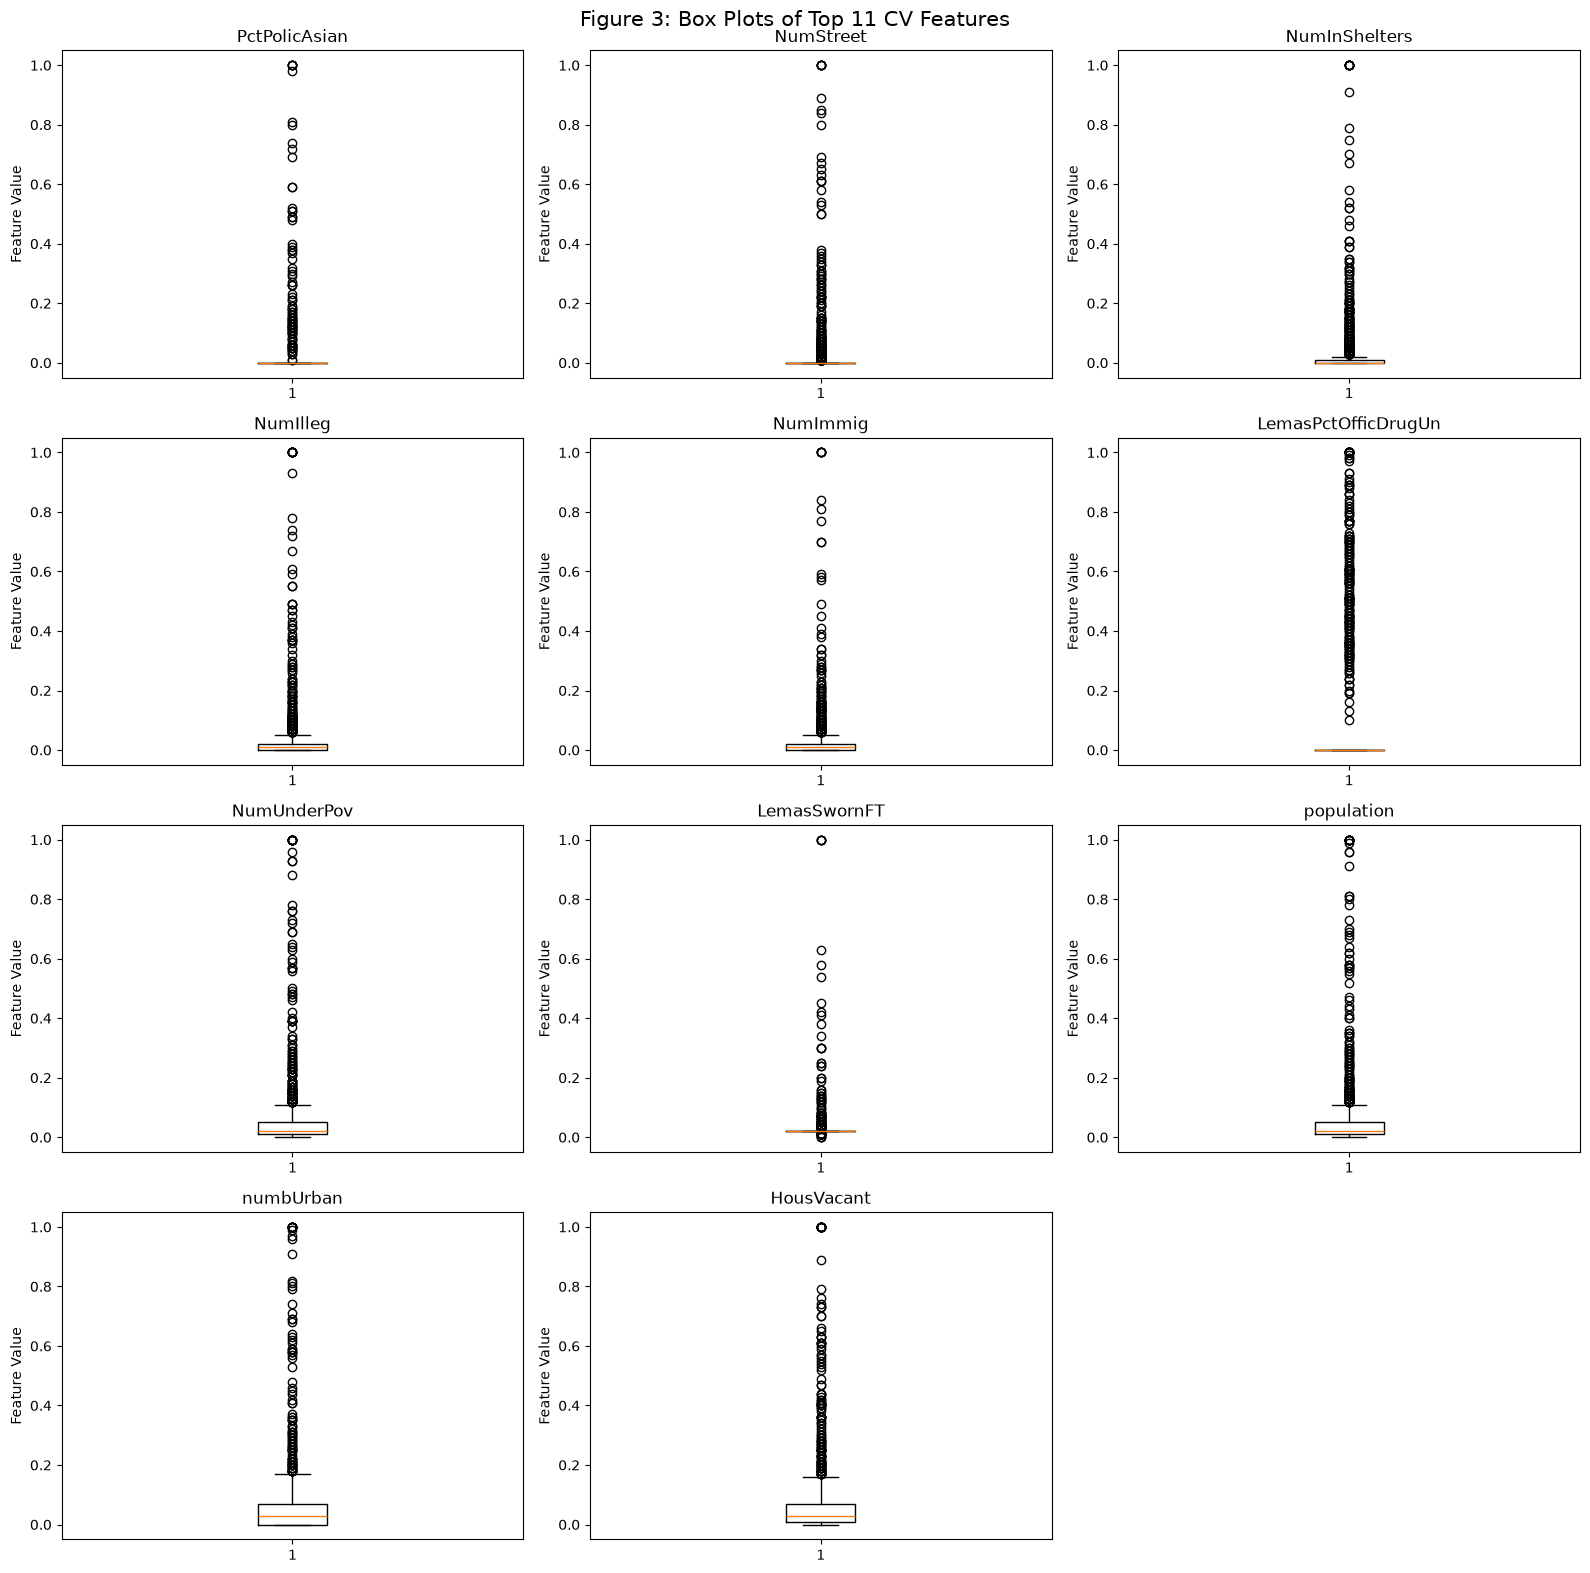

In [13]:
# Box plots of the selected features
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].boxplot(X_train[feature].dropna())

    axes[i].set_title(feature)
    axes[i].set_ylabel("Feature Value")

# Remov unused subplot
for j in range(len(top_features), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Figure 3: Box Plots of Top 11 CV Features",
             fontsize=15)

plt.tight_layout()
plt.show()

### Interpretation

The plots help understand potential relationships between the selected features and the target variable. 

But we cannot determine the statistical significance or predictive importance of these features only from the scatter plots. A high coefficient of variation shows high relative variability, but does not necessarily imply a strong relationship with the target variable.

We need more statistical analysis to evaluate feature significance.

## (f) Least Squares Linear Regression

In [14]:
# Fitting the least squares regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predicting on the test set
y_pred_linear = linear_model.predict(X_test)

# Calculating the test error
linear_mse = mean_squared_error(y_test, y_pred_linear)

print("Least Squares Test MSE:", linear_mse)

Least Squares Test MSE: 0.01796621542606732


## (g) Ridge Regression

In [15]:

#lambda values
alphas = np.logspace(-4, 4, 100)

# Ridge regression with 5-fold cross-validation
ridge_model = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=alphas, cv=5, scoring="neg_mean_squared_error")
)

ridge_model.fit(X_train, y_train)

# Predicting on test set
y_pred_ridge = ridge_model.predict(X_test)

# Calculating test error
ridge_mse = mean_squared_error(y_test, y_pred_ridge)

print("Optimal lambda:", ridge_model.named_steps["ridgecv"].alpha_)
print("Ridge Regression Test MSE:", ridge_mse)

Optimal lambda: 79.24828983539186
Ridge Regression Test MSE: 0.017431130507402397


## (h) LASSO Regression

In [16]:
# LASSO without standardization
lasso_model = LassoCV(
    cv=5,
    random_state=42,
    max_iter=100000
)

lasso_model.fit(X_train, y_train)

# Predictions and test error
y_pred_lasso = lasso_model.predict(X_test)

lasso_mse = mean_squared_error(y_test, y_pred_lasso)

# Selected features 
selected_features = X_train.columns[
    np.abs(lasso_model.coef_) > 1e-8
].tolist()

print("Optimal lambda:", lasso_model.alpha_)
print("LASSO Test MSE:", lasso_mse)
print("\nSelected features:")
print(selected_features)
print("Number of selected features:", len(selected_features))

Optimal lambda: 0.0001245408743775853
LASSO Test MSE: 0.01761776056977862

Selected features:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShe

In [17]:
# Standardized LASSO using a pipeline
lasso_scaled = make_pipeline(
    StandardScaler(),
    LassoCV(
        cv=5,
        random_state=42,
        max_iter=100000
    )
)

lasso_scaled.fit(X_train, y_train)

# Predictions and test error
y_pred_lasso_scaled = lasso_scaled.predict(X_test)

lasso_scaled_mse = mean_squared_error(
    y_test, y_pred_lasso_scaled
)

# Extracting fitted LASSO model
lasso_cv_scaled = lasso_scaled.named_steps["lassocv"]

# Selected features
selected_features_scaled = X_train.columns[
    np.abs(lasso_cv_scaled.coef_) > 1e-8
].tolist()

print("Optimal lambda:", lasso_cv_scaled.alpha_)
print("Standardized LASSO Test MSE:", lasso_scaled_mse)
print("\nSelected features:")
print(selected_features_scaled)
print("Number of selected features:", len(selected_features_scaled))

Optimal lambda: 0.0007630833878262516
Standardized LASSO Test MSE: 0.017682000986749824

Selected features:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBo

In [18]:
print("LASSO Comparison")
print("-" * 45)

print(f"Without standardization MSE: {lasso_mse:.6f}")
print(f"With standardization MSE:    {lasso_scaled_mse:.6f}")

if lasso_scaled_mse < lasso_mse:
    print("\nStandardized LASSO performs better.")
elif lasso_scaled_mse > lasso_mse:
    print("\nLASSO without standardization performs better.")
else:
    print("\nBoth models have equal test MSE.")

LASSO Comparison
---------------------------------------------
Without standardization MSE: 0.017618
With standardization MSE:    0.017682

LASSO without standardization performs better.


### Comparison
The LASSO model without standardization achieved a test MSE of **0.017618**, and the standardized LASSO model achieved a test MSE of **0.017682**.

The model without standardization performed slightly better. The standardized LASSO model selected 72 features. Overall, both models demonstrated similar predictive performance, which tells us that standardization had little impact on the test error for this dataset.

## (i) Principal Component Regression

In [19]:

# PCR pipeline
pcr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("regression", LinearRegression())
])

# number of components
max_components = min(
    X_train.shape[1],
    X_train.shape[0] - (X_train.shape[0] // 5 + 1)
)

# Cross-validation setup
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Searching for optimal M
param_grid = {
    "pca__n_components": list(range(1, max_components + 1))
}

pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Fitting PCR
pcr_search.fit(X_train, y_train)

# Best number of components
best_M = pcr_search.best_params_["pca__n_components"]

# Predicting on test set
y_pred_pcr = pcr_search.predict(X_test)

# Test error
pcr_mse = mean_squared_error(y_test, y_pred_pcr)

print("Optimal number of components (M):", best_M)
print("PCR Test MSE:", pcr_mse)

Optimal number of components (M): 60
PCR Test MSE: 0.01834952528616995


## (j) L1-Regularized Gradient Boosting

In [20]:
# Defining L1 regularization values
alphas = np.logspace(-4, 2, 15)

#XGBoost regression model
xgb = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    random_state=42,
    n_jobs=1
)

# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Selecting optimal alpha using cross-validation
grid_search = GridSearchCV(
    estimator=xgb,
    param_grid={"reg_alpha": alphas},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Best model and alpha
best_xgb = grid_search.best_estimator_
best_alpha = grid_search.best_params_["reg_alpha"]

# Predict on test set
y_pred_xgb = best_xgb.predict(X_test)

# Calculate test error
xgb_mse = mean_squared_error(y_test, y_pred_xgb)

print("Optimal alpha:", best_alpha)
print("Best CV MSE:", -grid_search.best_score_)
print("XGBoost Test MSE:", xgb_mse)

Optimal alpha: 0.03727593720314938
Best CV MSE: 0.019957727166126038
XGBoost Test MSE: 0.01618514965618314
